# Intel Natural Scene Image Classification Using CNN

## 1. Introduction

This project builds a Convolutional Neural Network (CNN) to classify natural-scene images into six classes: buildings, forest, glacier, mountain, sea, and street. CNNs are suitable for images because they learn visual features such as edges, colors, textures, and shapes automatically.
Saved outputs document the original training run. Rerunning the notebook retrains both models; results may vary. Install requirements.txt before running the cells in order.


In [ ]:
import json
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("TensorFlow version:", tf.__version__)


In [ ]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS_DIR = PROJECT_ROOT / "results"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)


In [2]:
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed:", SEED)

Random seed: 42


## 2. Dataset Overview and Class Analysis

The Intel Image Classification Dataset is downloaded directly from Kaggle using KaggleHub. It contains RGB images with an original size of 150 × 150 pixels. The code below locates the dataset, checks its folders, identifies the six classes, and counts the training and testing images in each class.

In [ ]:
path = kagglehub.dataset_download(
    "puneet6060/intel-image-classification"
)

DATASET_ROOT = Path(path)

print("Path to dataset files:")
print(DATASET_ROOT)

print("Files and folders inside the dataset:\n")

for item in DATASET_ROOT.iterdir():
    print(item.name)

In [ ]:
TRAIN_DIR = DATASET_ROOT / "seg_train" / "seg_train"
TEST_DIR = DATASET_ROOT / "seg_test" / "seg_test"
PRED_DIR = DATASET_ROOT / "seg_pred" / "seg_pred"

print("Training path:", TRAIN_DIR)
print("Testing path:", TEST_DIR)
print("Prediction path:", PRED_DIR)

print()
print("Training folder exists:", TRAIN_DIR.exists())
print("Testing folder exists:", TEST_DIR.exists())
print("Prediction folder exists:", PRED_DIR.exists())

In [5]:
class_names = sorted([
    folder.name
    for folder in TRAIN_DIR.iterdir()
    if folder.is_dir()
])

number_of_classes = len(class_names)

print("Class names:", class_names)
print("Number of classes:", number_of_classes)


Class names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of classes: 6


In [6]:
VALID_IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

def count_images(folder_path):
    return sum(
        1
        for file_path in folder_path.rglob("*")
        if (
            file_path.is_file()
            and file_path.suffix.lower() in VALID_IMAGE_EXTENSIONS
        )
    )


dataset_rows = []

for class_name in class_names:
    dataset_rows.append({
        "Class": class_name,
        "Training Images": count_images(TRAIN_DIR / class_name),
        "Testing Images": count_images(TEST_DIR / class_name)
    })

dataset_table = pd.DataFrame(dataset_rows)

print(dataset_table)

       Class  Training Images  Testing Images
0  buildings             2191             437
1     forest             2271             474
2    glacier             2404             553
3   mountain             2512             525
4        sea             2274             510
5     street             2382             501


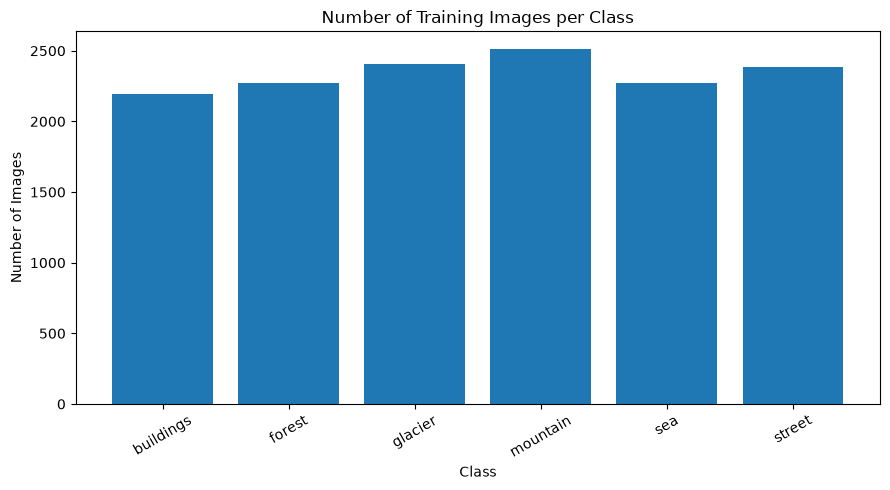

In [7]:
plt.figure(figsize=(9, 5))

plt.bar(
    dataset_table["Class"],
    dataset_table["Training Images"]
)

plt.title("Number of Training Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

## 3. Data Preprocessing

All images are resized to 128 × 128 pixels and kept in RGB format. The training data is divided into 80% training and 20% validation data. Images are loaded in batches of 32, while integer labels are generated automatically from the class-folder names. Pixel values are later normalized from 0–255 to 0–1 inside the model.

In [8]:
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
VALIDATION_SPLIT = 0.20

print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Validation split:", VALIDATION_SPLIT)

Image size: (128, 128)
Batch size: 32
Validation split: 0.2


In [9]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=VALIDATION_SPLIT,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int"
)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.


In [10]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=VALIDATION_SPLIT,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int"
)

Found 14034 files belonging to 6 classes.
Using 2806 files for validation.


In [11]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

Found 3000 files belonging to 6 classes.


In [12]:
class_names = train_ds.class_names
number_of_classes = len(class_names)

print("Classes detected by TensorFlow:")
print(class_names)

print("Number of classes:", number_of_classes)

Classes detected by TensorFlow:
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of classes: 6


In [13]:
for images, labels in train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("First 10 labels:", labels[:10].numpy())

Images shape: (32, 128, 128, 3)
Labels shape: (32,)
First 10 labels: [2 1 4 5 2 3 2 0 3 5]


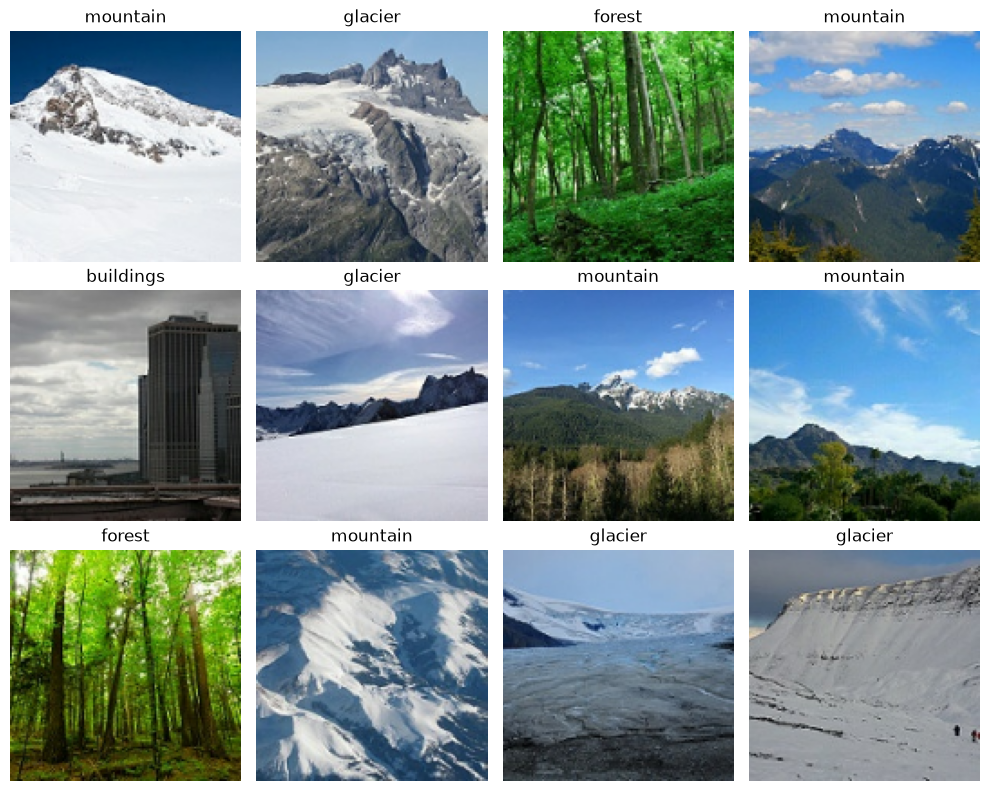

In [14]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for index in range(12):
        plt.subplot(3, 4, index + 1)

        image = images[index].numpy().astype("uint8")
        label_number = int(labels[index].numpy())
        label_name = class_names[label_number]

        plt.imshow(image)
        plt.title(label_name)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

## 4. Model Selection

A CNN was selected because convolutional layers preserve the spatial structure of images. They can learn local features such as edges and textures, then combine them into more complex scene patterns.

In [16]:
def create_cnn_model(
    dropout_rate=0.0,
    use_batch_normalization=False,
    learning_rate=0.001
):
    model = keras.Sequential(
        name="Intel_Scene_CNN"
    )

    model.add(
        layers.Input(
            shape=(128, 128, 3),
            name="input_image"
        )
    )

    model.add(
        layers.Rescaling(
            1.0 / 255,
            name="normalization"
        )
    )

    model.add(
        layers.Conv2D(
            filters=32,
            kernel_size=(3, 3),
            padding="same",
            activation="relu",
            name="conv_1"
        )
    )

    if use_batch_normalization:
        model.add(
            layers.BatchNormalization(
                name="batch_norm_1"
            )
        )

    model.add(
        layers.MaxPooling2D(
            pool_size=(2, 2),
            name="pool_1"
        )
    )

    model.add(
        layers.Conv2D(
            filters=64,
            kernel_size=(3, 3),
            padding="same",
            activation="relu",
            name="conv_2"
        )
    )

    if use_batch_normalization:
        model.add(
            layers.BatchNormalization(
                name="batch_norm_2"
            )
        )

    model.add(
        layers.MaxPooling2D(
            pool_size=(2, 2),
            name="pool_2"
        )
    )

    model.add(
        layers.Conv2D(
            filters=128,
            kernel_size=(3, 3),
            padding="same",
            activation="relu",
            name="conv_3"
        )
    )

    if use_batch_normalization:
        model.add(
            layers.BatchNormalization(
                name="batch_norm_3"
            )
        )

    model.add(
        layers.MaxPooling2D(
            pool_size=(2, 2),
            name="pool_3"
        )
    )

    model.add(
        layers.Flatten(
            name="flatten"
        )
    )

    model.add(
        layers.Dense(
            units=128,
            activation="relu",
            name="dense_128"
        )
    )

    if dropout_rate > 0:
        model.add(
            layers.Dropout(
                rate=dropout_rate,
                name="dropout"
            )
        )

    model.add(
        layers.Dense(
            units=number_of_classes,
            activation="softmax",
            name="output"
        )
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

## 5. Model Architecture

The model uses three convolutional layers with 32, 64, and 128 filters. Max-pooling reduces the image dimensions after each convolution. The extracted features are flattened and passed to a dense layer, followed by a six-neuron Softmax output layer. The model summary below displays the output shape and parameter count of every layer.

In [17]:
model_1 = create_cnn_model(
    dropout_rate=0.0,
    use_batch_normalization=False,
    learning_rate=0.001
)

model_1.summary()

early_stopping_1 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_1 = model_1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping_1]
)

Model: "Intel_Scene_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Rescaling)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,454 (16.36 MB)

 Trainable params: 4,288,454 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15


351/351 ━━━━━━━━━━━━━━━━━━━━ 80s 217ms/step - accuracy: 0.6226 - loss: 0.9728 - val_accuracy: 0.7377 - val_loss: 0.7325
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 77s 219ms/step - accuracy: 0.7707 - loss: 0.6330 - val_accuracy: 0.7962 - val_loss: 0.5855
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 77s 220ms/step - accuracy: 0.8246 - loss: 0.4878 - val_accuracy: 0.7969 - val_loss: 0.5842
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 78s 223ms/step - accuracy: 0.8799 - loss: 0.3439 - val_accuracy: 0.7940 - val_loss: 0.6104
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 78s 223ms/step - accuracy: 0.9248 - loss: 0.2199 - val_accuracy: 0.7994 - val_loss: 0.7581
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 84s 238ms/step - accuracy: 0.9486 - loss: 0.1535 - val_accuracy: 0.7979 - val_loss: 0.8646


## 6. Loss Function and Optimizer

Sparse categorical cross-entropy is used because there are six classes and the labels are stored as integer values. Adam is used to update the weights. The learning rate controls the size of each weight update during training.

In [18]:
model_2 = create_cnn_model(
    dropout_rate=0.5,
    use_batch_normalization=True,
    learning_rate=0.0005
)

model_2.summary()

early_stopping_2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_2 = model_2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping_2]
)

Model: "Intel_Scene_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Rescaling)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2                    │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_3                    │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289,350 (16.36 MB)

 Trainable params: 4,288,902 (16.36 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 137s 377ms/step - accuracy: 0.4929 - loss: 1.4135 - val_accuracy: 0.3154 - val_loss: 4.7088
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 132s 376ms/step - accuracy: 0.5727 - loss: 1.1393 - val_accuracy: 0.5353 - val_loss: 1.5200
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 131s 373ms/step - accuracy: 0.6193 - loss: 0.9904 - val_accuracy: 0.7213 - val_loss: 0.8592
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 133s 378ms/step - accuracy: 0.6568 - loss: 0.9079 - val_accuracy: 0.6568 - val_loss: 0.8853
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 129s 368ms/step - accuracy: 0.6822 - loss: 0.8523 - val_accuracy: 0.7730 - val_loss: 0.6691
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 132s 376ms/step - accuracy: 0.7141 - loss: 0.7674 - val_accuracy: 0.8015 - val_loss: 0.6180
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 137s 391ms/step - accuracy: 0.7304 - loss: 0.7154 - val_accuracy: 0.7929 - val_loss: 0.6326
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 137s 390ms/step - accuracy: 0.7447 -

## 7. Training Strategy and Hyperparameter Tuning

Two experiments are compared. The baseline model uses no dropout or batch normalization and a learning rate of 0.001. The regularized model uses dropout of 0.5, batch normalization, and a learning rate of 0.0005. Early stopping monitors validation loss and restores the best model weights.

In [19]:
best_val_accuracy_1 = max(
    history_1.history["val_accuracy"]
)

best_val_accuracy_2 = max(
    history_2.history["val_accuracy"]
)

best_val_loss_1 = min(
    history_1.history["val_loss"]
)

best_val_loss_2 = min(
    history_2.history["val_loss"]
)

comparison_table = pd.DataFrame({
    "Experiment": [
        "Experiment 1: Baseline",
        "Experiment 2: Regularized"
    ],
    "Dropout": [
        0.0,
        0.5
    ],
    "Batch Normalization": [
        False,
        True
    ],
    "Learning Rate": [
        0.001,
        0.0005
    ],
    "Best Validation Accuracy": [
        best_val_accuracy_1,
        best_val_accuracy_2
    ],
    "Best Validation Loss": [
        best_val_loss_1,
        best_val_loss_2
    ]
})

comparison_table

,Experiment,Dropout,Batch Normalization,Learning Rate,Best Validation Accuracy,Best Validation Loss
0,Experiment 1: Baseline,0.0,False,0.0010,0.799359,0.584185
1,Experiment 2: Regularized,0.5,True,0.0005,0.830007,0.522606


### Experiment Comparison

The following graphs compare validation accuracy and validation loss between the baseline and regularized experiments. A higher validation accuracy and a lower validation loss indicate better performance on unseen validation data.

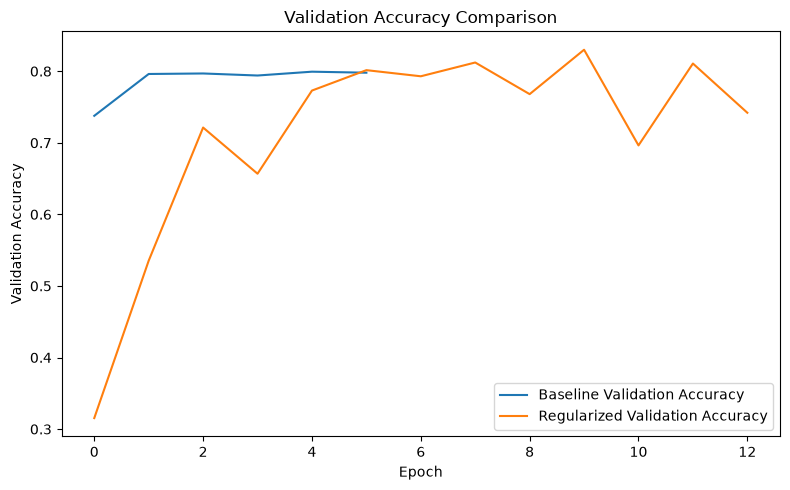

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_1.history["val_accuracy"],
    label="Baseline Validation Accuracy"
)

plt.plot(
    history_2.history["val_accuracy"],
    label="Regularized Validation Accuracy"
)

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

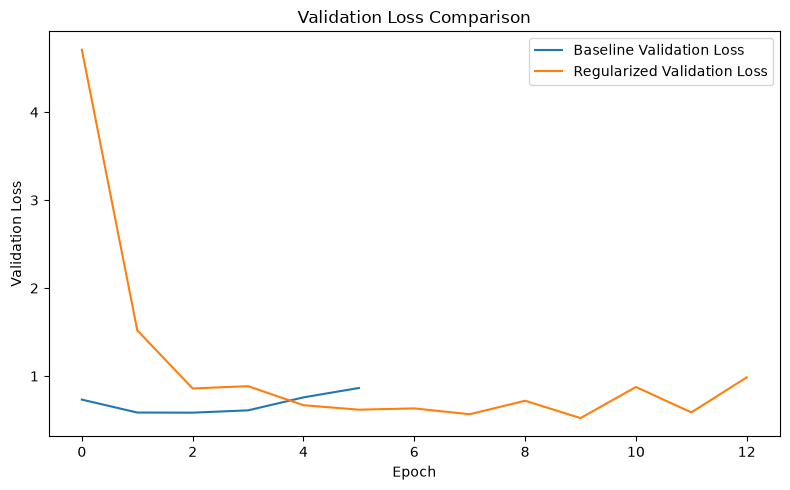

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_1.history["val_loss"],
    label="Baseline Validation Loss"
)

plt.plot(
    history_2.history["val_loss"],
    label="Regularized Validation Loss"
)

plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
if best_val_loss_2 < best_val_loss_1:
    best_model = model_2
    best_history = history_2
    best_experiment = "Experiment 2: Regularized"
else:
    best_model = model_1
    best_history = history_1
    best_experiment = "Experiment 1: Baseline"

print("Selected model:", best_experiment)

Selected model: Experiment 2: Regularized


## 8. Evaluation Metrics and Results

The model with the lowest validation loss is evaluated on the independent test set. In the recorded run, the regularized model achieved 82.40% test accuracy and 82.25% weighted F1-score on 3,000 images.


In [23]:
test_loss, test_accuracy = best_model.evaluate(
    test_ds
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy Percentage:", test_accuracy * 100, "%")

94/94 ━━━━━━━━━━━━━━━━━━━━ 7s 77ms/step - accuracy: 0.8240 - loss: 0.5389
Test Loss: 0.538864016532898
Test Accuracy: 0.8240000009536743
Test Accuracy Percentage: 82.40000009536743 %


In [24]:
prediction_probabilities = best_model.predict(
    test_ds
)

predicted_labels = np.argmax(
    prediction_probabilities,
    axis=1
)

print("Predictions shape:", prediction_probabilities.shape)
print("First 10 predicted labels:")
print(predicted_labels[:10])

94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step
Predictions shape: (3000, 6)
First 10 predicted labels:
[0 0 0 0 4 0 0 5 0 0]


In [25]:
true_labels = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

print("First 10 true labels:")
print(true_labels[:10])

print("Number of true labels:", len(true_labels))
print("Number of predictions:", len(predicted_labels))

First 10 true labels:
[0 0 0 0 0 0 0 0 0 0]
Number of true labels: 3000
Number of predictions: 3000


In [26]:
accuracy = accuracy_score(
    true_labels,
    predicted_labels
)

precision = precision_score(
    true_labels,
    predicted_labels,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    true_labels,
    predicted_labels,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    true_labels,
    predicted_labels,
    average="weighted",
    zero_division=0
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

Accuracy : 0.824
Precision: 0.8224022274895181
Recall   : 0.824
F1-score : 0.8224985990358512


In [27]:
report = classification_report(
    true_labels,
    predicted_labels,
    target_names=class_names,
    zero_division=0
)

print(report)

              precision    recall  f1-score   support

   buildings       0.80      0.74      0.77       437
      forest       0.90      0.98      0.94       474
     glacier       0.78      0.80      0.79       553
    mountain       0.79      0.73      0.76       525
         sea       0.84      0.83      0.84       510
      street       0.82      0.86      0.84       501

    accuracy                           0.82      3000
   macro avg       0.82      0.82      0.82      3000
weighted avg       0.82      0.82      0.82      3000



In [28]:
report_dictionary = classification_report(
    true_labels,
    predicted_labels,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_table = pd.DataFrame(
    report_dictionary
).transpose()

report_table

,precision,recall,f1-score,support
buildings,0.796569,0.743707,0.769231,437.000
forest,0.904854,0.983122,0.942366,474.000
glacier,0.783451,0.804702,0.793934,553.000
mountain,0.790890,0.727619,0.757937,525.000
sea,0.841584,0.833333,0.837438,510.000
street,0.823417,0.856287,0.839530,501.000
accuracy,0.824000,0.824000,0.824000,0.824
macro avg,0.823461,0.824795,0.823406,3000.000
weighted avg,0.822402,0.824000,0.822499,3000.000


In [29]:
class_results = report_table.loc[
    class_names,
    ["precision", "recall", "f1-score", "support"]
]

class_results = class_results.sort_values(
    by="f1-score",
    ascending=False
)

print("Classes ordered from strongest to weakest:")
class_results

Classes ordered from strongest to weakest:


,precision,recall,f1-score,support
forest,0.904854,0.983122,0.942366,474.0
street,0.823417,0.856287,0.839530,501.0
sea,0.841584,0.833333,0.837438,510.0
glacier,0.783451,0.804702,0.793934,553.0
buildings,0.796569,0.743707,0.769231,437.0
mountain,0.790890,0.727619,0.757937,525.0


In [30]:
confusion = confusion_matrix(
    true_labels,
    predicted_labels
)

print(confusion)

[[325  12   5   6  10  79]
 [  4 466   1   2   0   1]
 [  7   6 445  62  26   7]
 [ 14   6  82 382  39   2]
 [ 20   5  29  28 425   3]
 [ 38  20   6   3   5 429]]


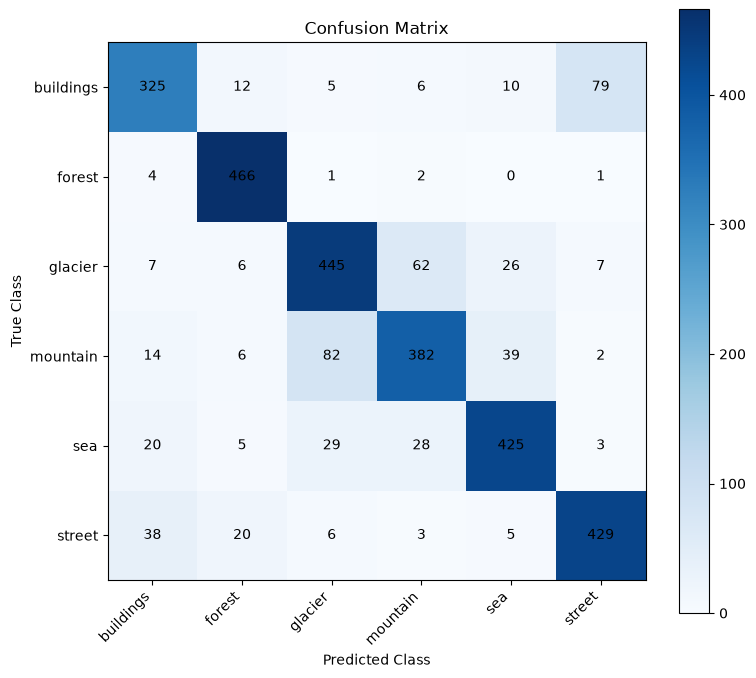

In [31]:
plt.figure(figsize=(8, 7))

plt.imshow(
    confusion,
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(
    range(number_of_classes),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(number_of_classes),
    class_names
)

for row in range(number_of_classes):
    for column in range(number_of_classes):
        plt.text(
            column,
            row,
            confusion[row, column],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

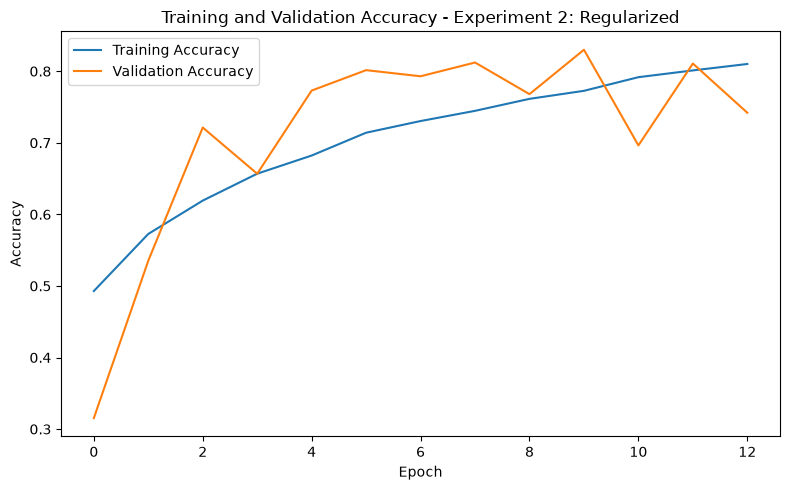

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    best_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    best_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title(
    f"Training and Validation Accuracy - {best_experiment}"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

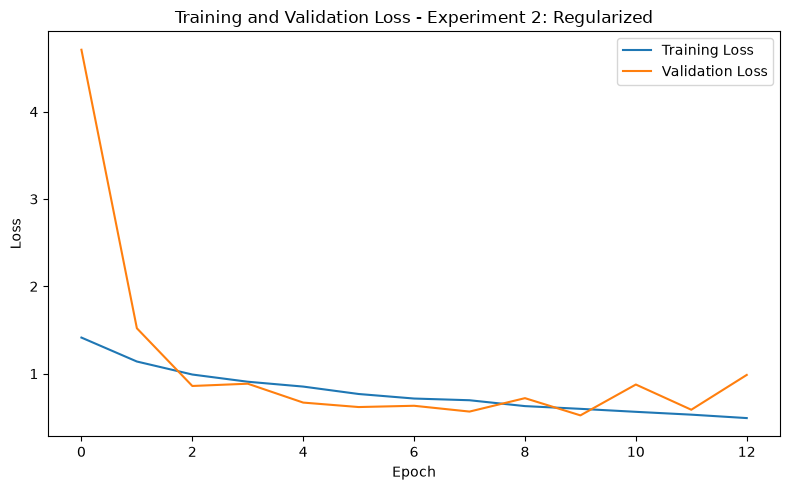

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(
    best_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    best_history.history["val_loss"],
    label="Validation Loss"
)

plt.title(
    f"Training and Validation Loss - {best_experiment}"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 9. Regularization and Overfitting Control

Overfitting occurs when training performance continues to improve while validation performance becomes worse. The code below measures the training-validation gap at the best epoch and also finds the largest gap that appeared during training. Early stopping restores the weights from the epoch with the lowest validation loss.

In [34]:
training_accuracies = np.array(
    best_history.history["accuracy"]
)

validation_accuracies = np.array(
    best_history.history["val_accuracy"]
)

validation_losses = np.array(
    best_history.history["val_loss"]
)

# The best epoch is the epoch with the lowest validation loss.
best_epoch_index = int(np.argmin(validation_losses))
best_epoch_number = best_epoch_index + 1

training_accuracy_at_best_epoch = (
    training_accuracies[best_epoch_index]
)

validation_accuracy_at_best_epoch = (
    validation_accuracies[best_epoch_index]
)

gap_at_best_epoch = (
    training_accuracy_at_best_epoch
    - validation_accuracy_at_best_epoch
)

# Find the largest training-validation gap using values from the same epoch.
epoch_gaps = training_accuracies - validation_accuracies
maximum_gap_index = int(np.argmax(epoch_gaps))
maximum_gap_epoch = maximum_gap_index + 1
maximum_gap_during_training = epoch_gaps[maximum_gap_index]

print("Best Epoch:", best_epoch_number)
print(
    "Training Accuracy at Best Epoch:",
    training_accuracy_at_best_epoch
)
print(
    "Validation Accuracy at Best Epoch:",
    validation_accuracy_at_best_epoch
)
print(
    "Gap at Best Epoch:",
    gap_at_best_epoch
)
print(
    "Maximum Gap During Training:",
    maximum_gap_during_training
)
print(
    "Maximum Gap Occurred at Epoch:",
    maximum_gap_epoch
)

Best Epoch: 10
Training Accuracy at Best Epoch: 0.7726219892501831
Validation Accuracy at Best Epoch: 0.8300071358680725
Gap at Best Epoch: -0.057385146617889404
Maximum Gap During Training: 0.1774793565273285
Maximum Gap Occurred at Epoch: 1


In [35]:
final_results = pd.DataFrame({
    "Metric": [
        "Selected Experiment",
        "Best Epoch",
        "Test Loss",
        "Test Accuracy",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-score",
        "Gap at Best Epoch",
        "Maximum Gap During Training"
    ],
    "Result": [
        best_experiment,
        best_epoch_number,
        test_loss,
        accuracy,
        precision,
        recall,
        f1,
        gap_at_best_epoch,
        maximum_gap_during_training
    ]
})

final_results

,Metric,Result
0,Selected Experiment,Experiment 2: Regularized
1,Best Epoch,10
2,Test Loss,0.538864
3,Test Accuracy,0.824
4,Weighted Precision,0.822402
5,Weighted Recall,0.824
6,Weighted F1-score,0.822499
7,Gap at Best Epoch,-0.057385
8,Maximum Gap During Training,0.177479


In [ ]:
comparison_table.to_csv(
    RESULTS_DIR / "experiment_comparison.csv",
    index=False
)

report_table.to_csv(
    RESULTS_DIR / "classification_report.csv"
)

final_results.to_csv(
    RESULTS_DIR / "final_results.csv",
    index=False
)

print("Result tables saved successfully.")

## 10. Challenges and Future Work

Some classes are visually similar. Mountain and glacier images may both contain snow and rocks, while street and buildings images may contain similar urban objects. The dense layer also contains many parameters, which can increase overfitting. Future improvements could include data augmentation, fewer dense parameters, an additional convolutional layer, or testing other dropout and learning-rate values.

In [ ]:
best_model.save(
    MODEL_DIR / "intel_scene_cnn.keras"
)

print("Model saved successfully.")
(MODEL_DIR / "class_names.json").write_text(json.dumps(class_names, indent=2))
